In [ ]:
# import clickhouse_connect
# import pandas as pd

# # 1. Connexion à ClickHouse
# client = clickhouse_connect.get_client(host='localhost', username='default', password='admin')

# # 2. Récupération des données
# query = "SELECT * FROM bourse.prices_analytics"
# result = client.query(query)

# # 3. Transformation en DataFrame (le format préféré du ML)
# df = pd.DataFrame(result.result_rows, columns=result.column_names)

# print(df.head())

In [1]:
import pandas as pd
df = pd.read_csv("dataset/dataset_bourse_ml.csv")

print(df.head())

     id        date symbole  prix_ouverture  prix_cloture  prix_bas  \
0  5370  2012-05-01       A           42.03     42.970000     41.80   
1  5840  2012-05-02       A           42.70     43.040000     42.30   
2  6310  2012-05-03       A           43.15     42.210000     42.18   
3  6780  2012-05-04       A           42.15     41.010002     40.96   
4  7250  2012-05-07       A           40.67     40.860000     40.27   

   prix_haut     volume  variation  volatilite  dollar_volume  \
0  43.270000  3615500.0   2.236498    1.470000   1.553580e+08   
1  43.100002  3348000.0   0.796253    0.800002   1.440979e+08   
2  43.150000  2398100.0  -2.178447    0.970000   1.012238e+08   
3  42.290000  3070200.0  -2.704622    1.330000   1.259089e+08   
4  41.090000  3658000.0   0.467175    0.820000   1.494659e+08   

                        nom      secteur           sous_secteur  \
0  Agilent Technologies Inc  Health Care  Health Care Equipment   
1  Agilent Technologies Inc  Health Care  Health

In [2]:
# 1. On s'assure que les données sont bien triées par date pour chaque symbole
df = df.sort_values(['symbole', 'date'])

In [3]:
# 2. On crée la cible : le prix de clôture du lendemain pour chaque symbole
df['target'] = df.groupby('symbole')['prix_cloture'].shift(-1)

In [4]:
# 3. Vérification visuelle
print(df[['symbole', 'date', 'prix_cloture', 'target']].head(1763))

       symbole        date  prix_cloture     target
237568       A  2010-01-04     31.300001  30.960001
237569       A  2010-01-05     30.960001  30.850000
237570       A  2010-01-06     30.850000  30.810000
237571       A  2010-01-07     30.810000  30.800000
237572       A  2010-01-08     30.800000  30.820002
...        ...         ...           ...        ...
1172         A  2016-12-27     46.510000  45.720000
1173         A  2016-12-28     45.720000  45.640000
1174         A  2016-12-29     45.640000  45.560000
1175         A  2016-12-30     45.560000        NaN
238154     AAL  2010-01-04      4.770000   5.310000

[1763 rows x 4 columns]


In [5]:
# On supprime uniquement les lignes où 'target' est vide
df = df.dropna(subset=['target'])

In [6]:
# Vérification : on regarde si le NaN de la ligne 1175 a disparu
print(df[df['symbole'] == 'A'].tail(5))

        id        date symbole  prix_ouverture  prix_cloture  prix_bas  \
1170  8265  2016-12-22       A           45.93         45.97     45.80   
1171  8765  2016-12-23       A           46.08         46.20     45.93   
1172  9265  2016-12-27       A           46.37         46.51     46.32   
1173  9765  2016-12-28       A           46.51         45.72     45.68   
1174   265  2016-12-29       A           45.68         45.64     45.57   

      prix_haut     volume  variation  volatilite  dollar_volume  \
1170      46.13   968300.0   0.087089        0.33     44512751.0   
1171      46.23   727700.0   0.260417        0.30     33619740.0   
1172      46.66  1535500.0   0.301919        0.34     71416105.0   
1173      46.70  1177300.0  -1.698559        1.02     53826156.0   
1174      46.00   891000.0  -0.087566        0.43     40665240.0   

                           nom      secteur           sous_secteur  \
1170  Agilent Technologies Inc  Health Care  Health Care Equipment   
1171  

In [9]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['symbole_n'] = le.fit_transform(df['symbole'])

In [10]:
df['date'] = pd.to_datetime(df['date'])
df['mois'] = df['date'].dt.month
df['jour_semaine'] = df['date'].dt.dayofweek

In [16]:
df.head()

,id,date,symbole,prix_ouverture,prix_cloture,prix_bas,prix_haut,volume,variation,volatilite,dollar_volume,nom,secteur,sous_secteur,siege,date_introduction,target,symbole_n,mois,jour_semaine
237568,252,2010-01-04,A,31.39,31.300001,31.13,31.630001,3815500.0,-0.286712,0.500001,1.194252e+08,Agilent Technologies Inc,Health Care,Health Care Equipment,"Santa Clara, California",2026-01-01,30.960001,0,1,0
237569,719,2010-01-05,A,31.21,30.960001,30.76,31.220001,4186000.0,-0.801022,0.460001,1.295986e+08,Agilent Technologies Inc,Health Care,Health Care Equipment,"Santa Clara, California",2026-01-01,30.850000,0,1,1
237570,1187,2010-01-06,A,30.85,30.850000,30.76,31.000002,3243700.0,0.000000,0.240002,1.000681e+08,Agilent Technologies Inc,Health Care,Health Care Equipment,"Santa Clara, California",2026-01-01,30.810000,0,1,2
237571,1655,2010-01-07,A,30.78,30.810000,30.50,30.820002,3095100.0,0.097466,0.320002,9.536003e+07,Agilent Technologies Inc,Health Care,Health Care Equipment,"Santa Clara, California",2026-01-01,30.800000,0,1,3
237572,2123,2010-01-08,A,30.64,30.800000,30.40,30.850000,3733900.0,0.522193,0.450000,1.150041e+08,Agilent Technologies Inc,Health Care,Health Care Equipment,"Santa Clara, California",2026-01-01,30.820002,0,1,4


In [17]:
from sklearn.preprocessing import MinMaxScaler

# 1. Sélection des colonnes que l'IA va regarder (X)
X_cols = ['symbole_n', 'mois', 'jour_semaine', 'prix_ouverture', 'prix_cloture', 
          'prix_bas', 'prix_haut', 'volume', 'variation', 'volatilite', 'dollar_volume']

X = df[X_cols]
y = df['target']

# 2. On "écrase" les échelles pour qu'elles soient toutes comparables
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print("Données normalisées (X_scaled) prêtes !")

Données normalisées (X_scaled) prêtes !


In [18]:
from sklearn.model_selection import train_test_split

# On sépare X_scaled et y en deux groupes
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

print(f"Lignes pour l'entraînement : {X_train.shape[0]}")
print(f"Lignes pour le test : {X_test.shape[0]}")

Lignes pour l'entraînement : 680610
Lignes pour le test : 170153


In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Création du modèle (on met 100 arbres pour commencer)
model = RandomForestRegressor(n_estimators=100, random_state=42)

# 2. Entraînement
print("Entraînement en cours...")
model.fit(X_train, y_train)

# 3. Prédiction sur les données de test
predictions = model.predict(X_test)

# 4. Évaluation
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print(f"Erreur moyenne (MAE) : {mae:.4f} $")
print(f"Score de précision (R2) : {r2:.4f}")

Entraînement en cours...
Erreur moyenne (MAE) : 0.8540 $
Score de précision (R2) : 0.9987


In [24]:
import numpy as np

# 1. On crée une matrice vide avec la même forme que nos features pour tromper le scaler
temp_matrix = np.zeros((len(X_test), len(X_cols)))

# 2. On place la colonne Prix_Actuel (index 4) dans cette matrice
temp_matrix[:, 4] = X_test[:, 4]

# 3. On applique l'inverse du scaler
X_test_unscaled = scaler.inverse_transform(temp_matrix)

# 4. On refait le tableau proprement
comparaison_finale = pd.DataFrame({
    'Prix_Aujourdhui': X_test_unscaled[:, 4], # Maintenant en dollars !
    'Vrai_Prix_Demain': y_test.values,
    'Prediction_IA': predictions
})

# 5. On ajoute la différence et le gain/perte prévu
comparaison_finale['Mouvement_Reel'] = comparaison_finale['Vrai_Prix_Demain'] - comparaison_finale['Prix_Aujourdhui']
comparaison_finale['Mouvement_IA'] = comparaison_finale['Prediction_IA'] - comparaison_finale['Prix_Aujourdhui']

print(comparaison_finale.head(10))

   Prix_Aujourdhui  Vrai_Prix_Demain  Prediction_IA  Mouvement_Reel  \
0        21.380000          21.39000      21.355899        0.010000   
1        35.640000          35.82000      35.639100        0.180000   
2        39.440044          39.55005      39.712100        0.110006   
3        34.420000          33.48000      34.216100       -0.940000   
4        32.140000          32.24000      32.186002        0.100000   
5        44.890000          45.44000      44.846400        0.550000   
6         4.710000           4.51000       4.706800       -0.200000   
7        50.510000          50.48000      50.445094       -0.030000   
8        77.050000          75.55000      77.027400       -1.500000   
9        22.065000          21.64000      21.999350       -0.425000   

   Mouvement_IA  
0     -0.024101  
1     -0.000900  
2      0.272056  
3     -0.203900  
4      0.046002  
5     -0.043600  
6     -0.003200  
7     -0.064906  
8     -0.022600  
9     -0.065650  


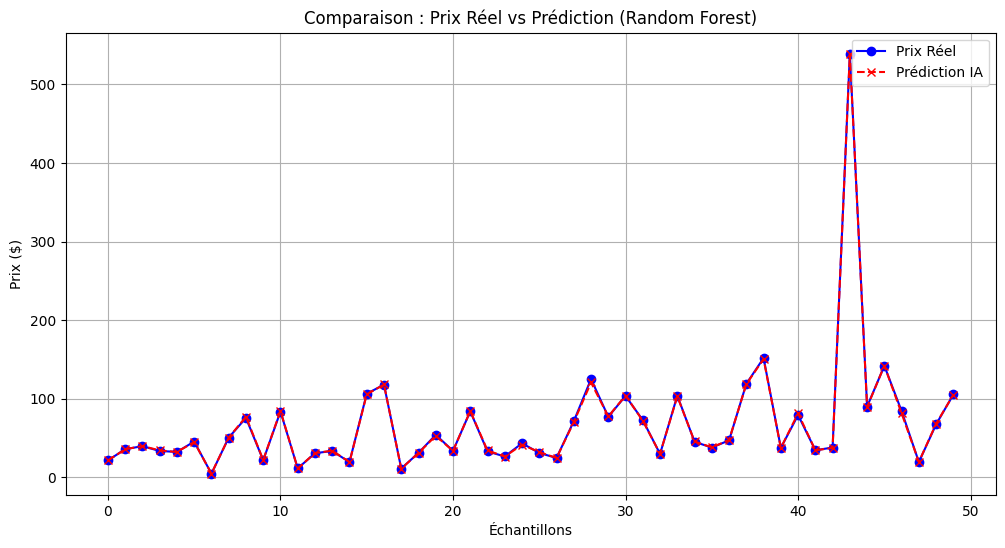

In [21]:
import matplotlib.pyplot as plt

# On prend les 50 premiers résultats du test pour que ce soit lisible
plt.figure(figsize=(12, 6))
plt.plot(y_test.values[:50], label='Prix Réel', color='blue', marker='o')
plt.plot(predictions[:50], label='Prédiction IA', color='red', linestyle='--', marker='x')

plt.title('Comparaison : Prix Réel vs Prédiction (Random Forest)')
plt.xlabel('Échantillons')
plt.ylabel('Prix ($)')
plt.legend()
plt.grid(True)
plt.show()

In [25]:
import joblib

# 1. Sauvegarder le modèle entraîné
joblib.dump(model, 'modele_bourse_rf.pkl')

# 2. Sauvegarder le scaler (très important pour dé-normaliser demain !)
joblib.dump(scaler, 'scaler_bourse.pkl')

print("✅ Modèle et Scaler sauvegardés avec succès !")

✅ Modèle et Scaler sauvegardés avec succès !


In [1]:
import joblib

# Charger le modèle et le scaler sans rien recalculer
model = joblib.load('modele_bourse_rf.pkl')
scaler = joblib.load('scaler_bourse.pkl')

print("🧠 Modèle chargé et prêt à prédire !")

FileNotFoundError: [Errno 2] No such file or directory: 'modele_bourse_rf.pkl'